# 02 · Exploratory Data Analysis
Which factors affect delivery time the most?

Data: `model_data.csv`, 12,645 cleaned orders (Bangalore, Mumbai, Chennai, Pune) with weather.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
FIG = '../reports/figures/'
T = 'Time_taken(min)'

def save(name):
    plt.tight_layout()
    plt.savefig(FIG + name, dpi=120)
    plt.show()

df = pd.read_csv('../data/processed/model_data.csv')
df.shape

(12645, 37)

## Step 1 · Target: delivery time

In [2]:
df[T].describe().round(1)

count    12645.0
mean        26.2
std          9.3
min         10.0
25%         19.0
50%         25.0
75%         32.0
max         54.0
Name: Time_taken(min), dtype: float64

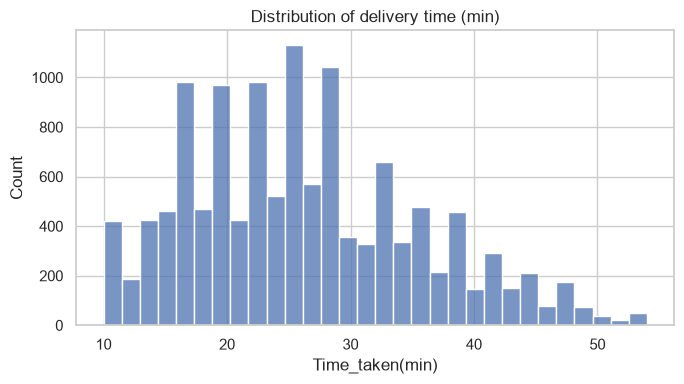

In [3]:
plt.figure(figsize=(7, 4))
sns.histplot(df[T], bins=30)
plt.title('Distribution of delivery time (min)')
save('01_target_hist.png')

## Step 2 · Traffic

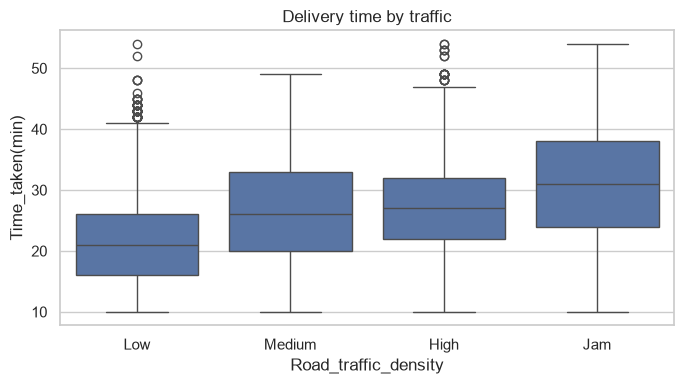

Road_traffic_density
High      27.1
Jam       31.0
Low       21.6
Medium    26.5
Name: Time_taken(min), dtype: float64

In [4]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='Road_traffic_density', y=T, order=['Low', 'Medium', 'High', 'Jam'])
plt.title('Delivery time by traffic')
save('02_traffic.png')
df.groupby('Road_traffic_density')[T].mean().round(1)

## Step 3 · Weather condition

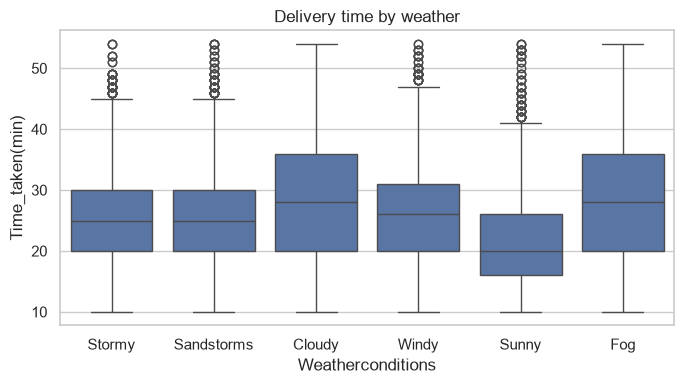

Weatherconditions
Cloudy        28.8
Fog           28.6
Sandstorms    25.7
Stormy        25.8
Sunny         22.0
Windy         26.0
Name: Time_taken(min), dtype: float64

In [5]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='Weatherconditions', y=T)
plt.title('Delivery time by weather')
save('03_weather.png')
df.groupby('Weatherconditions')[T].mean().round(1)

## Step 4 · Festival

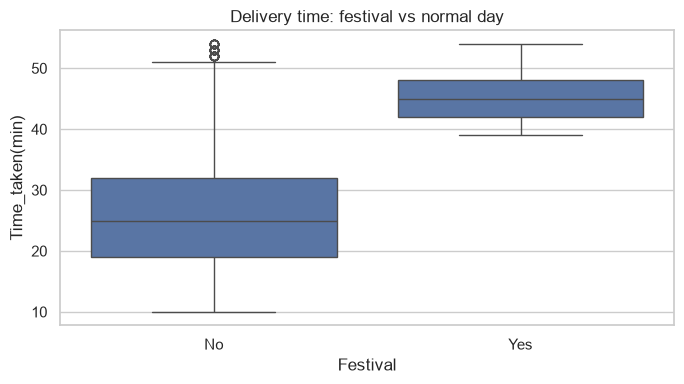

Festival
No     25.8
Yes    45.4
Name: Time_taken(min), dtype: float64

In [6]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='Festival', y=T)
plt.title('Delivery time: festival vs normal day')
save('04_festival.png')
df.groupby('Festival')[T].mean().round(1)

## Step 5 · Multiple deliveries per trip

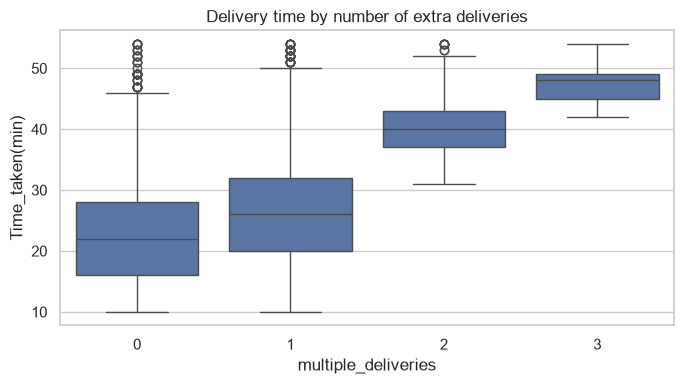

multiple_deliveries
0    22.9
1    26.6
2    40.3
3    47.5
Name: Time_taken(min), dtype: float64

In [7]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='multiple_deliveries', y=T)
plt.title('Delivery time by number of extra deliveries')
save('05_multiple_deliveries.png')
df.groupby('multiple_deliveries')[T].mean().round(1)

## Step 6 · City type and vehicle

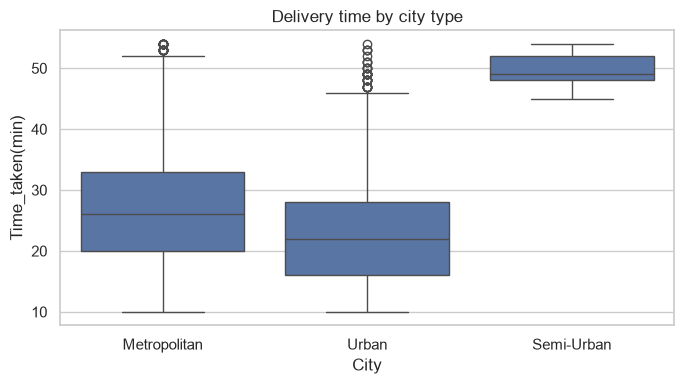

City
Metropolitan    27.0
Semi-Urban      49.4
Urban           22.9
Name: Time_taken(min), dtype: float64

In [8]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='City', y=T)
plt.title('Delivery time by city type')
save('06_city_type.png')
df.groupby('City')[T].mean().round(1)

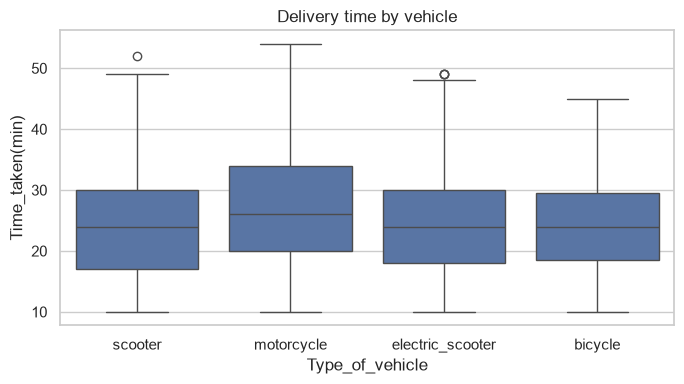

Type_of_vehicle
bicycle             24.2
electric_scooter    24.5
motorcycle          27.5
scooter             24.3
Name: Time_taken(min), dtype: float64

In [9]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='Type_of_vehicle', y=T)
plt.title('Delivery time by vehicle')
save('07_vehicle.png')
df.groupby('Type_of_vehicle')[T].mean().round(1)

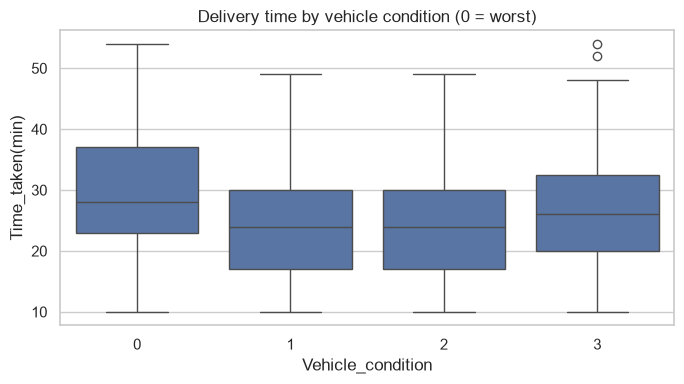

Vehicle_condition
0    29.9
1    24.3
2    24.2
3    26.8
Name: Time_taken(min), dtype: float64

In [10]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='Vehicle_condition', y=T)
plt.title('Delivery time by vehicle condition (0 = worst)')
save('08_vehicle_condition.png')
df.groupby('Vehicle_condition')[T].mean().round(1)

## Step 7 · Time of day

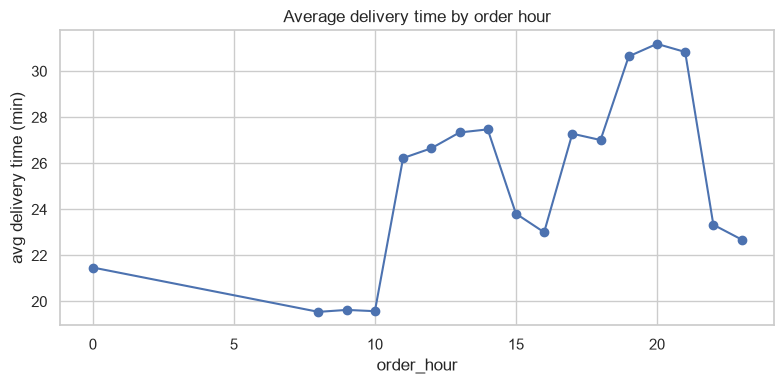

In [11]:
plt.figure(figsize=(8, 4))
df.groupby('order_hour')[T].mean().plot(marker='o')
plt.ylabel('avg delivery time (min)')
plt.title('Average delivery time by order hour')
save('09_hour.png')

## Step 8 · Rider and distance (numeric features)

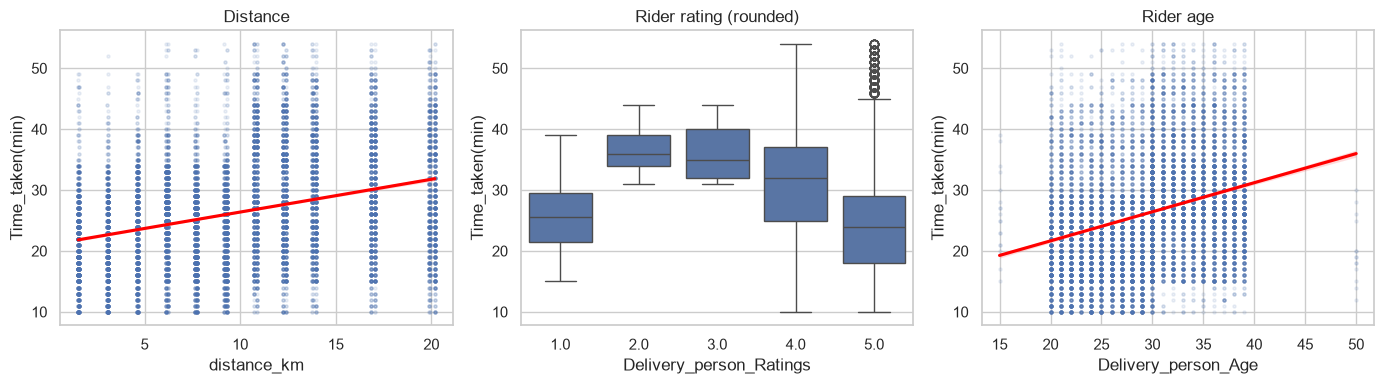

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.regplot(data=df, x='distance_km', y=T, ax=ax[0], scatter_kws={'alpha': .1, 's': 5}, line_kws={'color': 'red'})
sns.boxplot(data=df, x=df.Delivery_person_Ratings.round(), y=T, ax=ax[1])
sns.regplot(data=df, x='Delivery_person_Age', y=T, ax=ax[2], scatter_kws={'alpha': .1, 's': 5}, line_kws={'color': 'red'})
ax[0].set_title('Distance'); ax[1].set_title('Rider rating (rounded)'); ax[2].set_title('Rider age')
save('10_numeric.png')

## Step 9 · Real weather from Open-Meteo

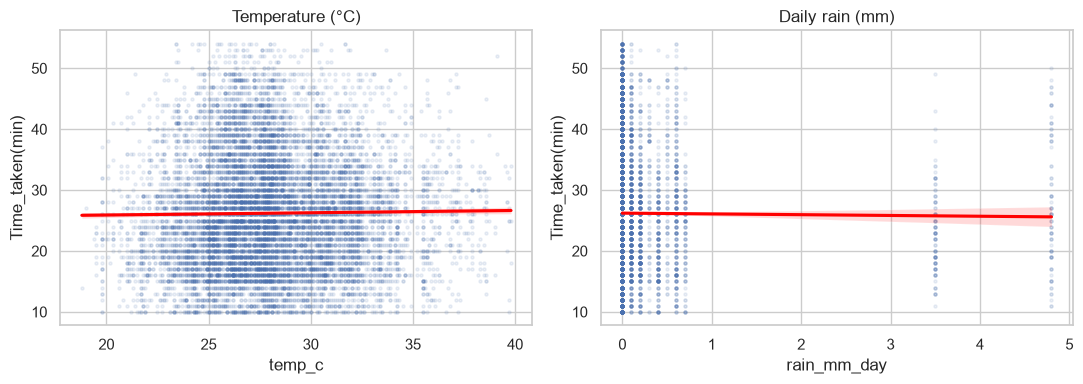

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.regplot(data=df, x='temp_c', y=T, ax=ax[0], scatter_kws={'alpha': .1, 's': 5}, line_kws={'color': 'red'})
sns.regplot(data=df, x='rain_mm_day', y=T, ax=ax[1], scatter_kws={'alpha': .1, 's': 5}, line_kws={'color': 'red'})
ax[0].set_title('Temperature (°C)'); ax[1].set_title('Daily rain (mm)')
save('11_open_meteo.png')

## Step 10 · Traffic × weather

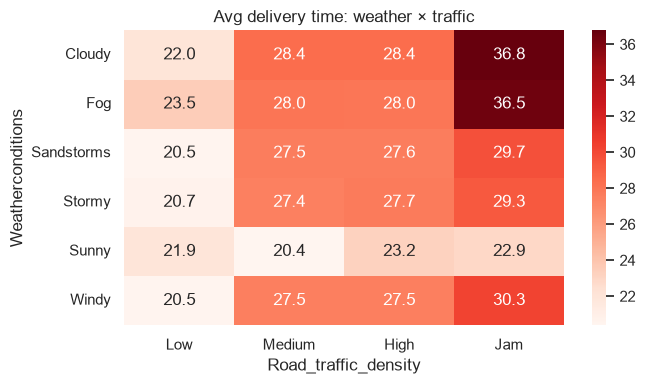

In [14]:
pivot = df.pivot_table(index='Weatherconditions', columns='Road_traffic_density', values=T)
pivot = pivot[['Low', 'Medium', 'High', 'Jam']]
plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='Reds')
plt.title('Avg delivery time: weather × traffic')
save('12_weather_traffic.png')

## Step 11 · Correlation

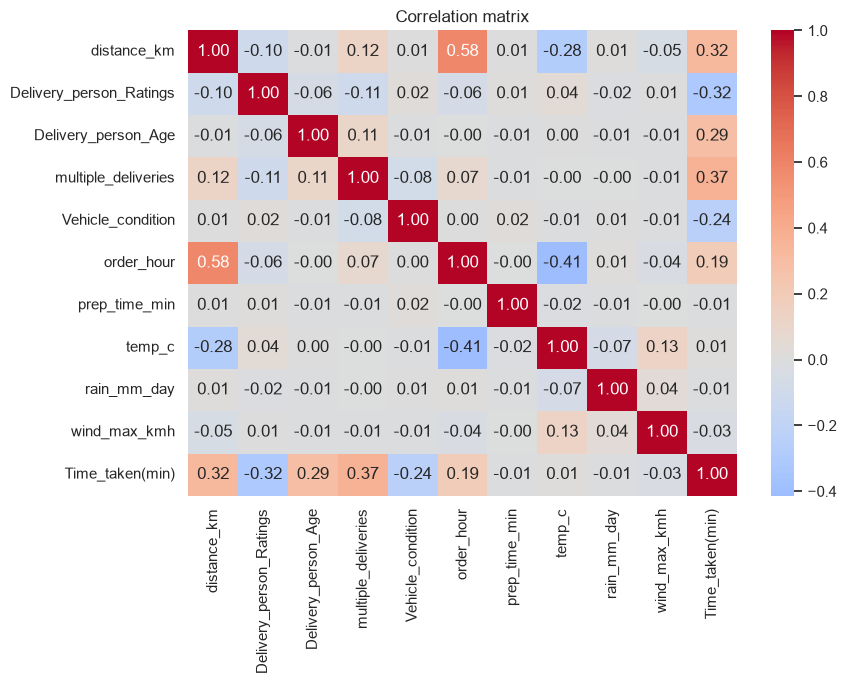

In [15]:
num = ['distance_km', 'Delivery_person_Ratings', 'Delivery_person_Age', 'multiple_deliveries',
       'Vehicle_condition', 'order_hour', 'prep_time_min', 'temp_c', 'rain_mm_day', 'wind_max_kmh', T]
plt.figure(figsize=(9, 7))
sns.heatmap(df[num].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
save('13_correlation.png')

## Step 12 · Zomato Bangalore (context only)
Restaurant-level data; it cannot be joined to orders, so it is only used as background.

51717 restaurant listings | 58.9 % accept online orders


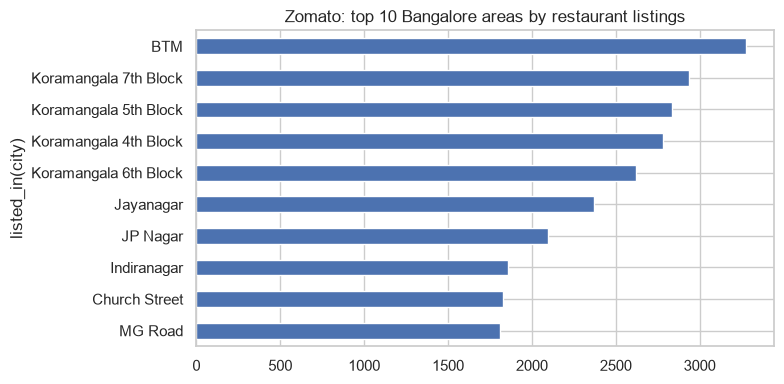

In [16]:
z = pd.read_csv('../data/raw/zomato/zomato.csv',
                usecols=['online_order', 'rate', 'approx_cost(for two people)', 'listed_in(city)'])
z['rate'] = pd.to_numeric(z['rate'].str.split('/').str[0], errors='coerce')
z['cost'] = pd.to_numeric(z['approx_cost(for two people)'].str.replace(',', ''), errors='coerce')
print(len(z), 'restaurant listings |', round((z.online_order == 'Yes').mean() * 100, 1), '% accept online orders')
top = z['listed_in(city)'].value_counts().head(10)
plt.figure(figsize=(8, 4))
top.plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Zomato: top 10 Bangalore areas by restaurant listings')
save('14_zomato_areas.png')

## Key findings
| Factor | Effect on avg delivery time |
|---|---|
| **Festival** | 25.8 → **45.4 min** (+~20 min), the single biggest jump |
| **Multiple deliveries** | 0 → 22.9, 1 → 26.6, 2 → 40.3, 3 → **47.5 min** |
| **Traffic** | Low 21.6 → Medium 26.5 → High 27.1 → **Jam 31.0 min** |
| **Weather condition** | Sunny 22.0 vs Fog/Cloudy ~28.7 min |
| **Time of day** | dinner peak 19–21h ≈ 31 min vs morning ≈ 19.5 min |
| **Vehicle condition** | condition 0 (worst) 29.9 vs 1–2 ≈ 24.3 min |
| **Distance / rating / age** | correlation +0.32 / −0.32 / +0.29 |
| City type | Urban 22.9, Metropolitan 27.0 (Semi-Urban 49.4 but only 41 orders) |

**Little or no effect:** order type, weekend, the 4 cities themselves, and the **Open-Meteo numeric weather** (temperature / rain / wind, |r| < 0.03). In this dataset the categorical weather label carries the signal, while measured weather barely does. Worth stating in the report as a limitation.

Relationships are step-like and interact: Cloudy/Fog + Jam ≈ 36.7 min, while Sunny stays ≈ 21–23 min at every traffic level, which suggests **Random Forest** should beat the linear models.